# Intel RealSense D435i Connection, Capture, and Distance Test

This notebook tests an Intel RealSense D435i camera end to end:

- Check Python dependencies
- Check connected RealSense devices
- Inspect sensors, streams, and depth scale
- Define helper functions for pipeline setup, alignment, visualization, and distance queries
- Capture one aligned color/depth frame
- Return center-point distance
- Live preview with click-to-measure

Recommended setup: connect the D435i directly to a USB 3 port, then run cells from top to bottom.

## 1. Dependency Check

Required packages:

- `pyrealsense2`
- `numpy`
- `opencv-python`
- `matplotlib`
- `ipywidgets` and `ipympl` for notebook-friendly interactive controls

If `pyrealsense2` is missing, install it in your active environment with:

```bash
pip install pyrealsense2 opencv-python matplotlib ipywidgets ipympl
```

In [1]:
import importlib.util
import sys

required_modules = {
    "pyrealsense2": "pyrealsense2",
    "numpy": "numpy",
    "cv2": "opencv-python",
    "matplotlib": "matplotlib",
    "ipywidgets": "ipywidgets",
    "ipympl": "ipympl",
}

missing = []
for module_name, package_name in required_modules.items():
    if importlib.util.find_spec(module_name) is None:
        missing.append(package_name)

print(f"Python executable: {sys.executable}")
if missing:
    print("Missing packages:", ", ".join(sorted(set(missing))))
    print("Install with: pip install " + " ".join(sorted(set(missing))))
else:
    print("All required packages are available.")

Python executable: /home/masais/miniconda3/envs/xinyu_zhuo/bin/python
All required packages are available.


In [2]:
import time
from dataclasses import dataclass
from typing import Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pyrealsense2 as rs

print("pyrealsense2 imported successfully.")

pyrealsense2 imported successfully.


## 2. Check Connected RealSense Devices

In [3]:
def list_realsense_devices(verbose: bool = True):
    """Return connected RealSense devices and print basic information."""
    ctx = rs.context()
    devices = ctx.query_devices()

    if verbose:
        print(f"Connected RealSense device count: {len(devices)}")

    for idx, dev in enumerate(devices):
        name = dev.get_info(rs.camera_info.name) if dev.supports(rs.camera_info.name) else "Unknown"
        serial = dev.get_info(rs.camera_info.serial_number) if dev.supports(rs.camera_info.serial_number) else "Unknown"
        firmware = dev.get_info(rs.camera_info.firmware_version) if dev.supports(rs.camera_info.firmware_version) else "Unknown"
        usb_type = dev.get_info(rs.camera_info.usb_type_descriptor) if dev.supports(rs.camera_info.usb_type_descriptor) else "Unknown"
        product_id = dev.get_info(rs.camera_info.product_id) if dev.supports(rs.camera_info.product_id) else "Unknown"

        if verbose:
            print("-" * 72)
            print(f"Device #{idx}")
            print(f"Name      : {name}")
            print(f"Serial    : {serial}")
            print(f"Firmware  : {firmware}")
            print(f"USB type  : {usb_type}")
            print(f"Product ID: {product_id}")
            print("Sensors:")
            for sensor in dev.query_sensors():
                sensor_name = sensor.get_info(rs.camera_info.name) if sensor.supports(rs.camera_info.name) else "Unknown sensor"
                print(f"  - {sensor_name}")

    return devices


devices = list_realsense_devices()
assert len(devices) > 0, "No RealSense device found. Check USB cable, power, permissions, and librealsense installation."

Connected RealSense device count: 1
------------------------------------------------------------------------
Device #0
Name      : Intel RealSense D435
Serial    : 317222075679
Firmware  : 5.16.0.1
USB type  : 3.2
Product ID: 0B07
Sensors:
  - Stereo Module
  - RGB Camera


## 3. Inspect Stream Profiles and Depth Scale

In [4]:
def print_device_stream_profiles(device_index: int = 0):
    """Print available stream profiles for one connected device."""
    ctx = rs.context()
    devices = ctx.query_devices()
    if len(devices) == 0:
        raise RuntimeError("No RealSense device found.")
    if device_index >= len(devices):
        raise IndexError(f"device_index={device_index} but only {len(devices)} device(s) connected.")

    dev = devices[device_index]
    print(f"Inspecting: {dev.get_info(rs.camera_info.name)} / serial {dev.get_info(rs.camera_info.serial_number)}")
    for sensor in dev.query_sensors():
        sensor_name = sensor.get_info(rs.camera_info.name) if sensor.supports(rs.camera_info.name) else "Unknown sensor"
        print("\n" + sensor_name)
        for profile in sensor.get_stream_profiles():
            stream = profile.stream_type()
            fmt = profile.format()
            fps = profile.fps()
            if profile.is_video_stream_profile():
                video_profile = profile.as_video_stream_profile()
                print(f"  {stream} {video_profile.width()}x{video_profile.height()} {fmt} {fps} FPS")
            else:
                print(f"  {stream} {fmt} {fps} FPS")


print_device_stream_profiles(device_index=0)

Inspecting: Intel RealSense D435 / serial 317222075679

Stereo Module
  stream.infrared 1280x800 format.y16 25 FPS
  stream.infrared 1280x800 format.y16 15 FPS
  stream.infrared 1280x800 format.y8 30 FPS
  stream.infrared 1280x800 format.y8 15 FPS
  stream.infrared 1280x720 format.y8 30 FPS
  stream.infrared 1280x720 format.y8 15 FPS
  stream.infrared 1280x720 format.y8 6 FPS
  stream.infrared 848x480 format.y8 90 FPS
  stream.infrared 848x480 format.y8 60 FPS
  stream.infrared 848x480 format.y8 30 FPS
  stream.infrared 848x480 format.y8 15 FPS
  stream.infrared 848x480 format.y8 6 FPS
  stream.infrared 848x100 format.y8 300 FPS
  stream.infrared 848x100 format.y8 100 FPS
  stream.infrared 640x480 format.y8 90 FPS
  stream.infrared 640x480 format.y8 60 FPS
  stream.infrared 640x480 format.y8 30 FPS
  stream.infrared 640x480 format.y8 15 FPS
  stream.infrared 640x480 format.y8 6 FPS
  stream.infrared 640x400 format.y16 25 FPS
  stream.infrared 640x400 format.y16 15 FPS
  stream.infrared

## 4. Helper Functions

In [5]:
@dataclass
class RealSenseConfig:
    width: int = 640
    height: int = 480
    fps: int = 30
    serial: Optional[str] = None
    align_to_color: bool = True


def create_pipeline(config: RealSenseConfig = RealSenseConfig()):
    """Create and start a RealSense pipeline for color and depth streams."""
    pipeline = rs.pipeline()
    rs_config = rs.config()

    if config.serial:
        rs_config.enable_device(config.serial)

    rs_config.enable_stream(rs.stream.depth, config.width, config.height, rs.format.z16, config.fps)
    rs_config.enable_stream(rs.stream.color, config.width, config.height, rs.format.bgr8, config.fps)

    profile = pipeline.start(rs_config)
    align = rs.align(rs.stream.color) if config.align_to_color else None

    depth_sensor = profile.get_device().first_depth_sensor()
    depth_scale = depth_sensor.get_depth_scale()

    return pipeline, profile, align, depth_scale


def stop_pipeline(pipeline):
    """Stop a pipeline while suppressing harmless cleanup errors."""
    try:
        pipeline.stop()
    except Exception as exc:
        print(f"Pipeline stop warning: {exc}")


def warmup_camera(pipeline, align=None, frames: int = 30):
    """Drop initial frames so auto-exposure can settle."""
    last_frames = None
    for _ in range(frames):
        last_frames = pipeline.wait_for_frames()
        if align is not None:
            last_frames = align.process(last_frames)
    return last_frames


def frames_to_numpy(frames):
    """Convert a frameset to color BGR, color RGB, and depth arrays."""
    depth_frame = frames.get_depth_frame()
    color_frame = frames.get_color_frame()
    if not depth_frame or not color_frame:
        raise RuntimeError("Could not get both depth and color frames.")

    depth_image = np.asanyarray(depth_frame.get_data())
    color_bgr = np.asanyarray(color_frame.get_data())
    color_rgb = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2RGB)
    return color_bgr, color_rgb, depth_image, depth_frame, color_frame


def capture_aligned_frame(config: RealSenseConfig = RealSenseConfig(), warmup_frames: int = 30):
    """Start camera, capture one aligned frame, and stop camera."""
    pipeline, profile, align, depth_scale = create_pipeline(config)
    try:
        frames = warmup_camera(pipeline, align, frames=warmup_frames)
        color_bgr, color_rgb, depth_image, depth_frame, color_frame = frames_to_numpy(frames)
        return {
            "color_bgr": color_bgr,
            "color_rgb": color_rgb,
            "depth_image": depth_image,
            "depth_frame": depth_frame,
            "color_frame": color_frame,
            "depth_scale": depth_scale,
            "profile": profile,
        }
    finally:
        stop_pipeline(pipeline)


def get_distance_m(depth_frame, x: int, y: int) -> float:
    """Return RealSense distance in meters at pixel (x, y)."""
    width = depth_frame.get_width()
    height = depth_frame.get_height()
    if not (0 <= x < width and 0 <= y < height):
        raise ValueError(f"Pixel ({x}, {y}) is outside frame size {width}x{height}.")
    return float(depth_frame.get_distance(int(x), int(y)))


def get_valid_median_distance_m(depth_frame, x: int, y: int, radius: int = 3) -> float:
    """Return median valid distance around a pixel, useful when one depth pixel is invalid."""
    values = []
    width = depth_frame.get_width()
    height = depth_frame.get_height()
    for yy in range(max(0, y - radius), min(height, y + radius + 1)):
        for xx in range(max(0, x - radius), min(width, x + radius + 1)):
            distance = depth_frame.get_distance(xx, yy)
            if distance > 0:
                values.append(distance)
    return float(np.median(values)) if values else 0.0


def depth_colormap(depth_image, alpha: float = 0.03):
    """Create an OpenCV color map for a raw uint16 depth image."""
    return cv2.applyColorMap(cv2.convertScaleAbs(depth_image, alpha=alpha), cv2.COLORMAP_JET)


def show_color_and_depth(color_rgb, depth_image, title: str = "RealSense frame"):
    """Display color and depth side by side in matplotlib."""
    depth_vis_bgr = depth_colormap(depth_image)
    depth_vis_rgb = cv2.cvtColor(depth_vis_bgr, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(color_rgb)
    axes[0].set_title("Color")
    axes[0].axis("off")
    axes[1].imshow(depth_vis_rgb)
    axes[1].set_title("Depth colormap")
    axes[1].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Capture One Frame and Return Center Distance

Frame size: 640x480
Depth scale: 0.00100000 meters per raw unit
Center pixel: (320, 240)
Center distance: 0.492 m
Center median distance within radius=5: 0.492 m


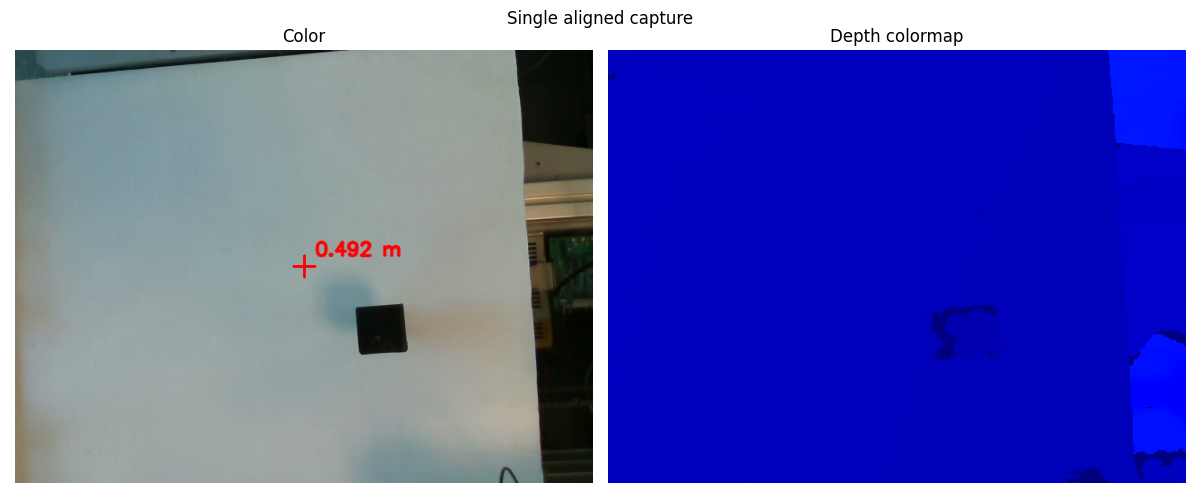

In [11]:
config = RealSenseConfig(width=640, height=480, fps=30)
frame_data = capture_aligned_frame(config, warmup_frames=30)

color_rgb = frame_data["color_rgb"]
depth_image = frame_data["depth_image"]
depth_frame = frame_data["depth_frame"]

h, w = depth_image.shape
cx, cy = w // 2, h // 2
center_distance = get_distance_m(depth_frame, cx, cy)
center_median_distance = get_valid_median_distance_m(depth_frame, cx, cy, radius=5)

print(f"Frame size: {w}x{h}")
print(f"Depth scale: {frame_data['depth_scale']:.8f} meters per raw unit")
print(f"Center pixel: ({cx}, {cy})")
print(f"Center distance: {center_distance:.3f} m")
print(f"Center median distance within radius=5: {center_median_distance:.3f} m")

preview = color_rgb.copy()
cv2.drawMarker(preview, (cx, cy), (255, 0, 0), markerType=cv2.MARKER_CROSS, markerSize=24, thickness=2)
cv2.putText(
    preview,
    f"{center_median_distance:.3f} m",
    (cx + 12, cy - 12),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.7,
    (255, 0, 0),
    2,
    cv2.LINE_AA,
)
show_color_and_depth(preview, depth_image, title="Single aligned capture")

## 6. Save a Test Capture

In [12]:
timestamp = time.strftime("%Y%m%d_%H%M%S")
color_path = f"realsense_pic/realsense_color_{timestamp}.png"
depth_vis_path = f"realsense_pic/realsense_depth_colormap_{timestamp}.png"
depth_raw_path = f"realsense_pic/realsense_depth_raw_{timestamp}.npy"

cv2.imwrite(color_path, frame_data["color_bgr"])
cv2.imwrite(depth_vis_path, depth_colormap(depth_image))
np.save(depth_raw_path, depth_image)

print("Saved:")
print(f"  {color_path}")
print(f"  {depth_vis_path}")
print(f"  {depth_raw_path}")

Saved:
  realsense_pic/realsense_color_20260618_135941.png
  realsense_pic/realsense_depth_colormap_20260618_135941.png
  realsense_pic/realsense_depth_raw_20260618_135941.npy


## 7. Notebook Click-to-Measure on One Captured Frame

Click anywhere on the displayed color image. The measured depth is read from the aligned depth frame.

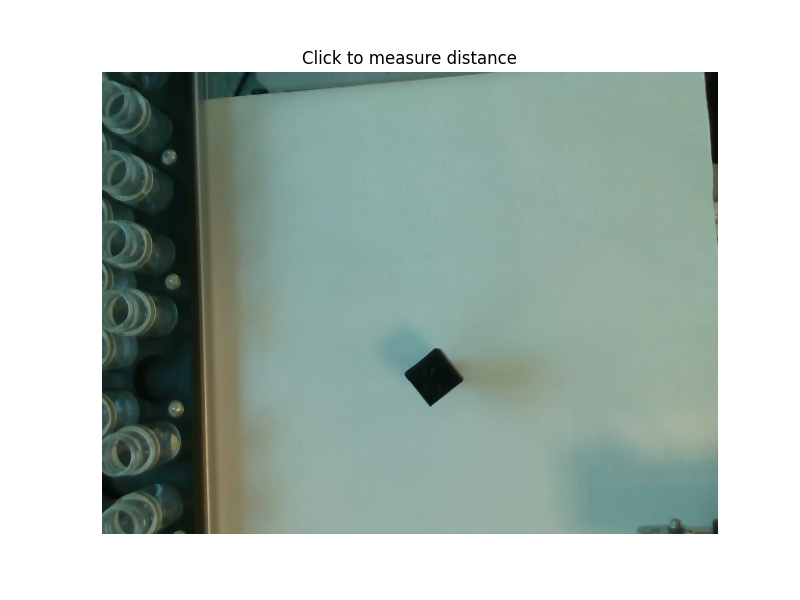

In [8]:
%matplotlib widget

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(color_rgb)
ax.set_title("Click to measure distance")
ax.axis("off")
marker_artist = None
text_artist = None

def on_matplotlib_click(event):
    global marker_artist, text_artist
    if event.inaxes != ax or event.xdata is None or event.ydata is None:
        return
    x = int(round(event.xdata))
    y = int(round(event.ydata))
    distance = get_valid_median_distance_m(depth_frame, x, y, radius=4)
    print(f"Clicked pixel ({x}, {y}) -> {distance:.3f} m")

    if marker_artist is not None:
        marker_artist.remove()
    if text_artist is not None:
        text_artist.remove()

    marker_artist = ax.plot(x, y, "r+", markersize=14, markeredgewidth=2)[0]
    text_artist = ax.text(
        x + 8,
        y - 8,
        f"{distance:.3f} m",
        color="white",
        fontsize=11,
        bbox={"facecolor": "red", "alpha": 0.75, "pad": 3},
    )
    fig.canvas.draw_idle()

cid = fig.canvas.mpl_connect("button_press_event", on_matplotlib_click)
plt.show()

## 8. Live Preview with Click-to-Measure

This cell opens an OpenCV desktop window. It is best for a local machine with GUI access.

Controls:

- Left click: measure distance at clicked pixel
- `s`: save current color/depth frame
- `q` or `Esc`: quit

In [9]:
def live_preview_click_to_measure(config: RealSenseConfig = RealSenseConfig(), warmup_frames: int = 30):
    """Run a live OpenCV preview. Click the color image to measure aligned depth."""
    window_name = "RealSense D435i live preview - click measure, s save, q quit"
    state = {
        "click": None,
        "last_color_bgr": None,
        "last_depth_image": None,
        "last_depth_frame": None,
    }

    def mouse_callback(event, x, y, flags, userdata):
        if event == cv2.EVENT_LBUTTONDOWN:
            state["click"] = (x, y)

    pipeline, profile, align, depth_scale = create_pipeline(config)
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.setMouseCallback(window_name, mouse_callback)

    try:
        warmup_camera(pipeline, align, frames=warmup_frames)
        print(f"Depth scale: {depth_scale:.8f} meters per raw unit")
        print("Live preview started. Left click to measure. Press s to save, q or Esc to quit.")

        while True:
            frames = pipeline.wait_for_frames()
            if align is not None:
                frames = align.process(frames)

            color_bgr, color_rgb, depth_image, depth_frame, color_frame = frames_to_numpy(frames)
            state["last_color_bgr"] = color_bgr.copy()
            state["last_depth_image"] = depth_image.copy()
            state["last_depth_frame"] = depth_frame

            depth_vis = depth_colormap(depth_image)
            display = np.hstack((color_bgr.copy(), depth_vis))

            if state["click"] is not None:
                x, y = state["click"]
                distance = get_valid_median_distance_m(depth_frame, x, y, radius=4)
                label = f"({x}, {y}) {distance:.3f} m"
                cv2.drawMarker(display, (x, y), (0, 0, 255), markerType=cv2.MARKER_CROSS, markerSize=24, thickness=2)
                cv2.putText(display, label, (x + 12, max(24, y - 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

                depth_x = x + config.width
                cv2.drawMarker(display, (depth_x, y), (255, 255, 255), markerType=cv2.MARKER_CROSS, markerSize=24, thickness=2)
                cv2.putText(display, label, (depth_x + 12, max(24, y - 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

            cv2.imshow(window_name, display)
            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord("s"):
                timestamp = time.strftime("%Y%m%d_%H%M%S")
                color_path = f"live_color_{timestamp}.png"
                depth_path = f"live_depth_raw_{timestamp}.npy"
                depth_vis_path = f"live_depth_colormap_{timestamp}.png"
                cv2.imwrite(color_path, color_bgr)
                np.save(depth_path, depth_image)
                cv2.imwrite(depth_vis_path, depth_vis)
                print(f"Saved {color_path}, {depth_path}, {depth_vis_path}")

    finally:
        stop_pipeline(pipeline)
        cv2.destroyWindow(window_name)
        print("Live preview stopped.")


# Run this cell to start live preview. Stop with q or Esc.
live_preview_click_to_measure(RealSenseConfig(width=640, height=480, fps=30), warmup_frames=30)

QFontDatabase: Cannot find font directory /home/masais/miniconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/masais/miniconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/masais/miniconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/masais/miniconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFon

Depth scale: 0.00100000 meters per raw unit
Live preview started. Left click to measure. Press s to save, q or Esc to quit.
Live preview stopped.


## 9. Optional: IMU Test for D435i

D435i includes accelerometer and gyroscope sensors. This quick test prints a few motion frames if the firmware and driver expose them correctly.

In [10]:
def test_d435i_imu(sample_count: int = 20):
    pipeline = rs.pipeline()
    cfg = rs.config()
    cfg.enable_stream(rs.stream.accel)
    cfg.enable_stream(rs.stream.gyro)
    pipeline.start(cfg)
    try:
        printed = 0
        while printed < sample_count:
            frames = pipeline.wait_for_frames()
            for frame in frames:
                if frame.is_motion_frame():
                    motion = frame.as_motion_frame().get_motion_data()
                    stream_name = frame.profile.stream_name()
                    print(f"{stream_name:>6}: x={motion.x: .5f}, y={motion.y: .5f}, z={motion.z: .5f}")
                    printed += 1
                    if printed >= sample_count:
                        break
    finally:
        stop_pipeline(pipeline)


# Uncomment to run the IMU test.
# test_d435i_imu(sample_count=20)

## 10. Troubleshooting Checklist

- No device found: reconnect USB, try another USB 3 port, and check `rs-enumerate-devices` from a terminal.
- Permission denied on Linux: install RealSense udev rules, unplug and reconnect the camera.
- Frame timeout: lower resolution/FPS, close other RealSense apps, and avoid USB hubs.
- Center distance is `0.000 m`: the pixel has invalid depth, so use the median helper or click on a textured object within range.
- OpenCV live window does not appear in remote Jupyter: use the notebook click-to-measure cell, or run the live preview locally with GUI access.
- D435i IMU fails while color/depth works: update librealsense and camera firmware, then retry.